# 02 · Validación y modelos

**Escenario de uso:** al cierre de cada hora *t* se estima la sílice del concentrado de esa hora.
Se conoce el proceso hasta *t*, pero el laboratorio entrega sus resultados (sílice del concentrado y
leyes de alimentación) con `LAB_DELAY` horas de retraso.

Reglas: split **temporal**, el test no se usa para ninguna decisión, y `% Iron Concentrate` queda
excluido por fuga (ver `01_eda`, Parte 3).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.model_selection import train_test_split

from src.config import DATA_PROCESSED, SEED, TARGET, TEST_START
from src.data import hourly_quality_flags, load_raw, runs
from src.evaluation import (compare_to_baseline, conformal_halfwidth, error_by_regime, interval_report,
                            regime_vs_baseline, regression_metrics, relative_improvement, time_series_cv)
from src.features import PROCESS_COLUMNS, build_features, hourly_aggregate
from src.models import fit_xgb_early_stopping, make_ridge
from src.viz import AQUA, BLUE, GRAY, ORANGE, TEXT, save, set_style

set_style()
pd.set_option("display.width", 160)
np.random.seed(SEED)

LAB_DELAY = 2  # horas entre la toma de muestra y el resultado de laboratorio (supuesto)

## 1. Datos y features

In [2]:
raw_path, flags_path = DATA_PROCESSED / "raw.parquet", DATA_PROCESSED / "flags_horarios.parquet"
if raw_path.exists() and flags_path.exists():
    df, flags = pd.read_parquet(raw_path), pd.read_parquet(flags_path)
else:  # permite correr este notebook sin haber corrido 01_eda
    df = load_raw()
    flags = hourly_quality_flags(df)

X_all, y_all, usable = build_features(df, flags, lab_delay=LAB_DELAY)
X, y = X_all[usable], y_all[usable]
print(f"Features: {X.shape[1]} | horas utilizables: {len(X)}")

Features: 102 | horas utilizables: 3326


## 2. Split temporal

- **Test**: desde `TEST_START` hasta el final (último tramo, ~5,5 semanas). Ningún hiperparámetro se elige con él. Las comparaciones por grupos de
  features (sección 6), retraso (sección 8) y régimen (sección 10) sí se miden en test: son descriptivas, no
  una selección de modelo.
- **Dentro del train**: `TimeSeriesSplit` de 5 folds (cada fold entrena con el pasado y valida en el tramo
  siguiente, con 6 h de separación para que los rezagos no crucen la frontera). Sirve para elegir
  hiperparámetros y para ver qué tan estable es el error en el tiempo.

In [3]:
is_test = X.index >= TEST_START
X_train, y_train, X_test, y_test = X[~is_test], y[~is_test], X[is_test], y[is_test]
print(f"Train: {len(X_train)} h  {X_train.index.min():%Y-%m-%d} → {X_train.index.max():%Y-%m-%d}")
print(f"Test:  {len(X_test)} h  {X_test.index.min():%Y-%m-%d} → {X_test.index.max():%Y-%m-%d}")
print(f"Sílice media train {y_train.mean():.2f} vs test {y_test.mean():.2f}")

Train: 2586 h  2017-03-10 → 2017-07-31
Test:  740 h  2017-08-04 → 2017-09-09
Sílice media train 2.19 vs test 2.21


## 3. Baselines

- **Media**: la media de la sílice en el train, constante.
- **Persistencia**: el último ensayo disponible (con `LAB_DELAY` h de retraso). Es lo que el operador ya tiene
  en pantalla sin ningún modelo; **este es el baseline que hay que superar**.

In [4]:
predictions = {
    "Media (baseline)": pd.Series(y_train.mean(), index=y_test.index),
    "Persistencia (baseline)": X_test["silica_ultimo"],
}
cv_results = {
    "Media (baseline)": time_series_cv(lambda Xt, yt, Xv: np.full(len(Xv), yt.mean()), X_train, y_train),
    "Persistencia (baseline)": time_series_cv(lambda Xt, yt, Xv: Xv["silica_ultimo"].to_numpy(), X_train, y_train),
}

## 4. Modelos

### 4a. Ridge
`StandardScaler` dentro del `Pipeline`: en cada fold el escalador se ajusta solo con los datos de
entrenamiento de ese fold. `alpha` se elige por MAE promedio en el `TimeSeriesSplit`.

El Pipeline incluye un **recorte a ±4σ** después del escalado. Sin él, el primer fold (que entrena solo
con marzo y mediados de abril, cuando varios flujos de aire estaban congelados o fijos en un setpoint)
ve en validación valores de aire a decenas de σ y el modelo lineal extrapola sin control. La celda
siguiente lo muestra.

In [5]:
first_fold = time_series_cv(
    lambda Xt, yt, Xv: make_ridge(100, clip_sigma=np.inf).fit(Xt, yt).predict(Xv), X_train, y_train)
print("Ridge SIN recorte, MAE por fold:", first_fold["MAE"].round(2).tolist())

Ridge SIN recorte, MAE por fold: [8.17, 0.71, 0.46, 0.69, 0.64]


In [6]:
alpha_grid = [0.1, 1, 10, 100, 1000, 3000, 10000]
alpha_cv = {
    a: time_series_cv(lambda Xt, yt, Xv, a=a: make_ridge(a).fit(Xt, yt).predict(Xv), X_train, y_train)["MAE"]
    for a in alpha_grid
}
alpha_table = pd.DataFrame({a: {"MAE_cv_media": s.mean(), "MAE_cv_std": s.std()} for a, s in alpha_cv.items()}).T
best_alpha = alpha_table["MAE_cv_media"].idxmin()
print("alpha elegido:", best_alpha)
alpha_table.round(3)

alpha elegido: 1000.0


,MAE_cv_media,MAE_cv_std
0.1,1.067,0.785
1.0,0.914,0.549
10.0,0.796,0.360
100.0,0.705,0.201
1000.0,0.695,0.178
3000.0,0.729,0.197
10000.0,0.772,0.199


In [7]:
ridge = make_ridge(best_alpha).fit(X_train, y_train)
predictions["Ridge"] = pd.Series(ridge.predict(X_test), index=y_test.index)
cv_results["Ridge"] = time_series_cv(lambda Xt, yt, Xv: make_ridge(best_alpha).fit(Xt, yt).predict(Xv),
                                     X_train, y_train)

### 4b. XGBoost con early stopping

El early stopping usa el **último 20 % del train** (en el tiempo) como validación, nunca el test.
Hiperparámetros conservadores (árboles poco profundos, submuestreo, `min_child_weight`) porque hay
~2600 horas y ~100 features.

Elegido el número de árboles, se **reentrena con todo el train**: si no, el modelo final perdería el tramo más
reciente (julio). Esta corrección llegó en una revisión que ya había visto el test, así que se justifica aquí
solo con la validación cruzada interna.

In [8]:
def xgb_fit_predict(Xt, yt, Xv):
    return fit_xgb_early_stopping(Xt, yt).predict(Xv)

cv_results["XGBoost"] = time_series_cv(xgb_fit_predict, X_train, y_train)

xgb = fit_xgb_early_stopping(X_train, y_train)
print("Árboles elegidos por early stopping:", xgb.n_estimators)
predictions["XGBoost"] = pd.Series(xgb.predict(X_test), index=y_test.index)

Árboles elegidos por early stopping: 118


In [9]:
refit_check = pd.DataFrame({
    "Sin reentrenar": time_series_cv(lambda Xt, yt, Xv: fit_xgb_early_stopping(Xt, yt, refit=False).predict(Xv),
                                     X_train, y_train)["MAE"],
    "Reentrenado": cv_results["XGBoost"]["MAE"],
})
print("MAE por fold dentro del train; media:", refit_check.mean().round(3).to_dict())
refit_check.round(3).T

MAE por fold dentro del train; media: {'Sin reentrenar': 0.694, 'Reentrenado': 0.682}


,0,1,2,3,4
Sin reentrenar,0.785,0.841,0.516,0.705,0.623
Reentrenado,0.784,0.869,0.465,0.681,0.611


## 5. Resultados

In [10]:
cv_summary = pd.DataFrame({name: {"MAE_cv_media": r["MAE"].mean(), "MAE_cv_std": r["MAE"].std()}
                           for name, r in cv_results.items()}).T

results = pd.DataFrame({name: regression_metrics(y_test, p) for name, p in predictions.items()}).T
results["mejora_vs_media"] = results["MAE"].apply(lambda m: relative_improvement(m, results.loc["Media (baseline)", "MAE"]))
results["mejora_vs_persistencia"] = results["MAE"].apply(
    lambda m: relative_improvement(m, results.loc["Persistencia (baseline)", "MAE"]))
results = results.join(cv_summary)
results.round(3)

,MAE,RMSE,R2,mejora_vs_media,mejora_vs_persistencia,MAE_cv_media,MAE_cv_std
Media (baseline),0.826,1.051,-0.000,0.000,-0.272,0.861,0.132
Persistencia (baseline),0.650,0.931,0.215,0.214,0.000,0.658,0.133
Ridge,0.650,0.880,0.299,0.214,-0.000,0.695,0.178
XGBoost,0.644,0.846,0.352,0.221,0.009,0.682,0.156


In [11]:
cv_by_fold = pd.DataFrame({name: r.set_index("fold")["MAE"] for name, r in cv_results.items()})
cv_by_fold.index = [f"{r.desde:%d-%b} → {r.hasta:%d-%b}" for r in cv_results["Ridge"].itertuples()]
print("MAE por fold del TimeSeriesSplit (dentro del train):")
cv_by_fold.round(3)

MAE por fold del TimeSeriesSplit (dentro del train):


,Media (baseline),Persistencia (baseline),Ridge,XGBoost
15-Apr → 09-May,0.894,0.822,0.847,0.784
09-May → 31-May,1.071,0.627,0.861,0.869
31-May → 19-Jun,0.740,0.459,0.425,0.465
19-Jun → 11-Jul,0.833,0.715,0.697,0.681
11-Jul → 31-Jul,0.765,0.667,0.642,0.611


### ¿Las diferencias son reales?

Diferencia pareada de error absoluto contra la persistencia (positiva = gana el modelo), con IC 95 % por
bootstrap de bloques de 48 h: los errores horarios están autocorrelacionados y remuestrear horas sueltas
daría intervalos demasiado angostos. Si el IC incluye el cero, la diferencia no se distingue del ruido.
`dif_MAE` y los IC están en puntos de % SiO₂; `mejora` es relativa al error de la persistencia.

In [12]:
baseline_test = predictions["Persistencia (baseline)"]
significance = pd.DataFrame({name: compare_to_baseline(y_test, predictions[name], baseline_test)
                             for name in ["Ridge", "XGBoost"]}).T
significance.round(3)

,dif_MAE,IC95_inf,IC95_sup,mejora
Ridge,-0.000,-0.037,0.040,-0.000
XGBoost,0.006,-0.025,0.038,0.009


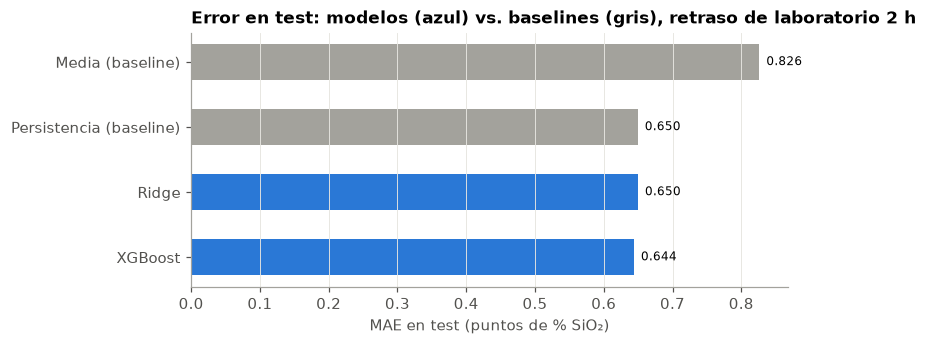

In [13]:
fig, ax = plt.subplots(figsize=(7, 3))
order = list(results.index)
colors = [GRAY, GRAY, BLUE, BLUE]
ax.barh(order, results["MAE"], color=colors, height=0.55)
for i, name in enumerate(order):
    ax.text(results.loc[name, "MAE"] + 0.01, i, f"{results.loc[name, 'MAE']:.3f}", va="center", fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("MAE en test (puntos de % SiO₂)")
ax.set_title(f"Error en test: modelos (azul) vs. baselines (gris), retraso de laboratorio {LAB_DELAY} h")
ax.grid(axis="y", visible=False)
save(fig, "04_mae_modelos")
plt.show()

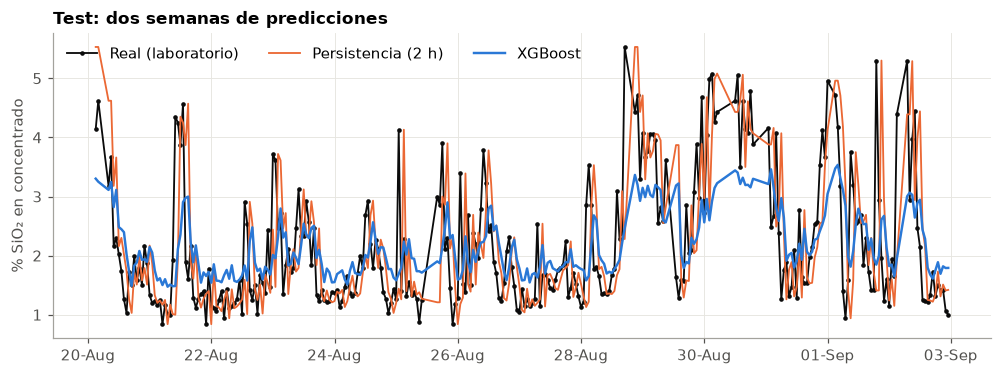

In [14]:
window = y_test.loc["2017-08-20":"2017-09-02"].index
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(window, y_test[window], color=TEXT, lw=1.2, marker="o", ms=2, label="Real (laboratorio)")
ax.plot(window, predictions["Persistencia (baseline)"][window], color=ORANGE, lw=1.2, label=f"Persistencia ({LAB_DELAY} h)")
ax.plot(window, predictions["XGBoost"][window], color=BLUE, lw=1.6, label="XGBoost")
ax.set_ylabel("% SiO₂ en concentrado")
ax.legend(frameon=False, ncol=3, loc="upper left")
ax.xaxis.set_major_locator(mdates.DayLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%b"))
ax.set_title("Test: dos semanas de predicciones")
save(fig, "04_predicciones_test")
plt.show()

## 6. ¿Qué aporta el proceso? Grupos de features

Mismo split y mismos modelos, cambiando solo las features disponibles.

In [15]:
silica_cols = [c for c in X.columns if c.startswith("silica_") or c == "horas_desde_ensayo"]
feed_cols = [c for c in X.columns if c.endswith("_disponible")]
process_cols = [c for c in X.columns if c not in silica_cols + feed_cols]
groups = {
    "Solo historia de sílice": silica_cols,
    "Solo proceso + alimentación": process_cols + feed_cols,
    "Todo": list(X.columns),
}
ablation = {}
for name, cols in groups.items():
    r = make_ridge(best_alpha).fit(X_train[cols], y_train)
    g = fit_xgb_early_stopping(X_train[cols], y_train)
    gain = compare_to_baseline(y_test, pd.Series(g.predict(X_test[cols]), index=y_test.index), baseline_test)
    ablation[name] = {"n_features": len(cols),
                      "MAE_ridge": regression_metrics(y_test, r.predict(X_test[cols]))["MAE"],
                      "MAE_xgb": regression_metrics(y_test, g.predict(X_test[cols]))["MAE"],
                      "dif_MAE_xgb": gain["dif_MAE"],
                      "IC95_inf": gain["IC95_inf"], "IC95_sup": gain["IC95_sup"]}
pd.DataFrame(ablation).T.round(3)

,n_features,MAE_ridge,MAE_xgb,dif_MAE_xgb,IC95_inf,IC95_sup
Solo historia de sílice,5.0,0.639,0.639,0.011,-0.016,0.037
Solo proceso + alimentación,97.0,0.819,0.879,-0.229,-0.313,-0.144
Todo,102.0,0.650,0.644,0.006,-0.025,0.038


## 7. ¿Cuánto se inflaría el score con un split aleatorio?

### 7a. Split aleatorio a nivel de fila (20 s): el error clásico en este dataset
Cada hora tiene ~180 filas con **el mismo valor de sílice** y lecturas de proceso casi idénticas.
Si se mezclan las filas al azar, casi todas las horas del test tienen filas "hermanas" en el train:
el modelo reconoce la hora y copia su sílice. Mismo XGBoost, mismas columnas crudas de proceso,
solo cambia cómo se parte.

In [16]:
valid_hours = flags.index[~(flags["target_interpolado"] | flags["target_repetido"] | flags["hora_congelada"])]
rows = df[df["date"].isin(valid_hours)]
raw_features = PROCESS_COLUMNS + ["% Iron Feed", "% Silica Feed"]

def row_level_xgb():
    from xgboost import XGBRegressor
    return XGBRegressor(n_estimators=300, max_depth=6, learning_rate=0.1, tree_method="hist",
                        random_state=SEED, n_jobs=-1)

Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(rows[raw_features], rows[TARGET], test_size=0.2,
                                              random_state=SEED, shuffle=True)
row_random = regression_metrics(yr_te, row_level_xgb().fit(Xr_tr, yr_tr).predict(Xr_te))

row_is_test = rows["date"] >= TEST_START
row_temporal = regression_metrics(
    rows.loc[row_is_test, TARGET],
    row_level_xgb().fit(rows.loc[~row_is_test, raw_features], rows.loc[~row_is_test, TARGET])
                   .predict(rows.loc[row_is_test, raw_features]))
pd.DataFrame({"Split aleatorio por fila": row_random, "Split temporal": row_temporal}).T.round(3)

,MAE,RMSE,R2
Split aleatorio por fila,0.394,0.552,0.711
Split temporal,0.853,1.112,-0.112


### 7b. Split aleatorio a nivel de hora, con nuestras features
Con las features horarias la inflación es mucho menor: la sílice de la hora *t* nunca está entre las
features (solo con ≥ `LAB_DELAY` h de rezago), así que no hay nada que "copiar". Lo que queda es el
efecto de entrenar con horas futuras del mismo régimen.

In [17]:
X_rtr, X_rte, y_rtr, y_rte = train_test_split(X, y, test_size=0.2, random_state=SEED, shuffle=True)
random_split = {
    "Ridge": regression_metrics(y_rte, make_ridge(best_alpha).fit(X_rtr, y_rtr).predict(X_rte)),
    "XGBoost": regression_metrics(y_rte, fit_xgb_early_stopping(X_rtr, y_rtr).predict(X_rte)),
}
inflation = pd.DataFrame({
    "MAE_split_aleatorio": {k: v["MAE"] for k, v in random_split.items()},
    "MAE_split_temporal": results.loc[["Ridge", "XGBoost"], "MAE"],
    "R2_split_aleatorio": {k: v["R2"] for k, v in random_split.items()},
    "R2_split_temporal": results.loc[["Ridge", "XGBoost"], "R2"],
})
inflation["error_subestimado_%"] = 100 * (1 - inflation["MAE_split_aleatorio"] / inflation["MAE_split_temporal"])
inflation.round(3)

,MAE_split_aleatorio,MAE_split_temporal,R2_split_aleatorio,R2_split_temporal,error_subestimado_%
Ridge,0.635,0.650,0.304,0.299,2.264
XGBoost,0.602,0.644,0.352,0.352,6.516


## 8. Sensibilidad al retraso de laboratorio

`LAB_DELAY` es un supuesto. ¿Cómo cambia el valor del modelo si el laboratorio es más rápido o más lento?

In [18]:
delay_rows = []
for delay in [1, 2, 3, 4, 6]:
    Xd_all, yd_all, ud = build_features(df, flags, lab_delay=delay)
    Xd, yd = Xd_all[ud], yd_all[ud]
    test_d = Xd.index >= TEST_START
    model_d = fit_xgb_early_stopping(Xd[~test_d], yd[~test_d])
    silica_d = [c for c in Xd.columns if c.startswith("silica_") or c == "horas_desde_ensayo"]
    model_silica_d = fit_xgb_early_stopping(Xd.loc[~test_d, silica_d], yd[~test_d])
    gain_all = compare_to_baseline(yd[test_d], pd.Series(model_d.predict(Xd[test_d]), index=yd[test_d].index),
                                   Xd.loc[test_d, "silica_ultimo"])
    gain_silica = compare_to_baseline(yd[test_d], pd.Series(model_silica_d.predict(Xd.loc[test_d, silica_d]),
                                                            index=yd[test_d].index),
                                      Xd.loc[test_d, "silica_ultimo"])
    delay_rows.append({
        "lab_delay_h": delay,
        "MAE_media": regression_metrics(yd[test_d], np.full(test_d.sum(), yd[~test_d].mean()))["MAE"],
        "MAE_persistencia": regression_metrics(yd[test_d], Xd.loc[test_d, "silica_ultimo"])["MAE"],
        "MAE_xgb_solo_silica": regression_metrics(yd[test_d], model_silica_d.predict(Xd.loc[test_d, silica_d]))["MAE"],
        "MAE_xgb": regression_metrics(yd[test_d], model_d.predict(Xd[test_d]))["MAE"],
        "dif_todo": gain_all["dif_MAE"], "IC95_inf_todo": gain_all["IC95_inf"], "IC95_sup_todo": gain_all["IC95_sup"],
        "dif_silica": gain_silica["dif_MAE"], "IC95_inf_silica": gain_silica["IC95_inf"],
        "IC95_sup_silica": gain_silica["IC95_sup"],
    })
delay_table = pd.DataFrame(delay_rows).set_index("lab_delay_h")
delay_table.round(3)

,MAE_media,MAE_persistencia,MAE_xgb_solo_silica,MAE_xgb,dif_todo,IC95_inf_todo,IC95_sup_todo,dif_silica,IC95_inf_silica,IC95_sup_silica
lab_delay_h,,,,,,,,,,
1,0.827,0.517,0.527,0.561,-0.044,-0.074,-0.015,-0.010,-0.038,0.013
2,0.826,0.650,0.639,0.644,0.006,-0.025,0.038,0.011,-0.016,0.037
3,0.828,0.755,0.706,0.714,0.041,-0.018,0.097,0.049,-0.001,0.096
4,0.833,0.855,0.761,0.761,0.094,0.025,0.161,0.093,0.033,0.150
6,0.836,0.969,0.814,0.856,0.113,0.007,0.226,0.155,0.074,0.239


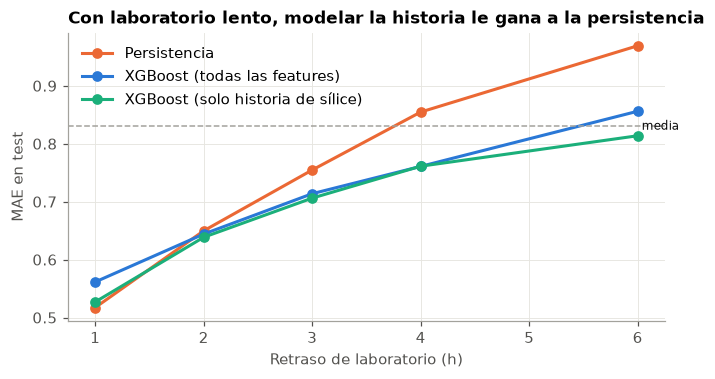

In [19]:
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(delay_table.index, delay_table["MAE_persistencia"], color=ORANGE, marker="o", lw=2, label="Persistencia")
ax.plot(delay_table.index, delay_table["MAE_xgb"], color=BLUE, marker="o", lw=2, label="XGBoost (todas las features)")
ax.plot(delay_table.index, delay_table["MAE_xgb_solo_silica"], color=AQUA, marker="o", lw=2,
        label="XGBoost (solo historia de sílice)")
ax.axhline(delay_table["MAE_media"].mean(), color=GRAY, ls="--", lw=1)
ax.text(delay_table.index.max(), delay_table["MAE_media"].mean(), " media", va="center", fontsize=8, color=TEXT)
ax.set_xlabel("Retraso de laboratorio (h)")
ax.set_ylabel("MAE en test")
ax.legend(frameon=False)
ax.set_title("Con laboratorio lento, modelar la historia le gana a la persistencia")
save(fig, "04_sensibilidad_retraso")
plt.show()

## 9. Guardar predicciones de test (para el análisis de error)

In [20]:
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
test_out = pd.DataFrame({"real": y_test, **{k: v for k, v in predictions.items()}})
test_out.to_parquet(DATA_PROCESSED / "predicciones_test.parquet")
test_out.head()

,real,Media (baseline),Persistencia (baseline),Ridge,XGBoost
date,,,,,
2017-08-04 01:00:00,2.41,2.186311,1.88,1.752086,1.990169
2017-08-04 02:00:00,1.95,2.186311,1.67,1.726576,2.014230
2017-08-04 03:00:00,2.05,2.186311,2.41,1.925628,2.208495
2017-08-04 04:00:00,3.68,2.186311,1.95,1.925843,2.269282
2017-08-04 05:00:00,3.84,2.186311,2.05,2.028713,2.260316


---
# Parte 2 · Análisis de error

Modelo de referencia: **XGBoost con todas las features** (`LAB_DELAY` = 2 h), comparado con la persistencia
y Ridge. Todo se evalúa en el test.

## 10. Error por régimen de operación

Terciles (calculados sobre el test) de dos variables que definen el régimen:
- **Sílice en la alimentación**: qué tan difícil viene el mineral. Se usa el valor horario registrado,
  porque aquí describe el régimen; no es una feature.
- **Flujo de amina**: cuánto colector se está dosificando.

In [21]:
hourly_full = hourly_aggregate(df, flags)
feed = hourly_full["% Silica Feed"]
feed_run_len = feed.groupby((feed != feed.shift()).cumsum()).transform("size")
feed_reliable = feed.where(feed_run_len <= 24)  # tramos > 24 h constantes = arrastre, no medición

feed_runs_test = runs(feed.loc[y_test.index.min():].dropna())
print("Tramos de ley de alimentación constante > 24 h dentro del test (excluidos del análisis por régimen):")
feed_runs_test.query("n > 24")

Tramos de ley de alimentación constante > 24 h dentro del test (excluidos del análisis por régimen):


,inicio,fin,n,valor
7,2017-08-07 01:00:00,2017-08-15 00:00:00,192,25.31
13,2017-08-16 16:00:00,2017-08-18 06:00:00,39,13.32


In [22]:
eval_preds = {k: predictions[k] for k in ["Persistencia (baseline)", "Ridge", "XGBoost"]}

regime_feed = error_by_regime(y_test, eval_preds, feed_reliable)
regime_amine = error_by_regime(y_test, eval_preds, X_test["Amina Flow"])
print("MAE por tercil de % Silica Feed (solo horas con ley confiable):")
display(regime_feed.round(3))
print("MAE por tercil de flujo de amina:")
display(regime_amine.round(3))

MAE por tercil de % Silica Feed (solo horas con ley confiable):


,n_horas,rango,Persistencia (baseline),Ridge,XGBoost
% Silica Feed,,,,,
bajo,182,1.3–12.9,0.553,0.532,0.529
medio,177,13.0–17.7,0.752,0.818,0.784
alto,174,17.8–33.4,0.783,0.658,0.667


MAE por tercil de flujo de amina:


,n_horas,rango,Persistencia (baseline),Ridge,XGBoost
Amina Flow,,,,,
bajo,247,268.9–448.9,0.481,0.544,0.551
medio,246,449.0–534.2,0.638,0.660,0.658
alto,247,534.5–737.0,0.830,0.746,0.723


Los mismos regímenes con IC 95 % contra la persistencia. Son seis grupos elegidos mirando el error en test:
un IC que excluye el cero es una **hipótesis a confirmar con otro periodo**, no un resultado cerrado.

In [23]:
regime_ci = pd.concat({
    (variable, modelo): regime_vs_baseline(y_test, predictions[modelo], baseline_test, regime)
    for variable, regime in [("SiO2 alimentación", feed_reliable), ("Amina", X_test["Amina Flow"])]
    for modelo in ["Ridge", "XGBoost"]})
regime_ci.round(3)

n_horas  dif_MAE  IC95_inf  IC95_sup  mejora
SiO2 alimentación Ridge   bajo     182.0    0.021    -0.016     0.058   0.038
                          medio    177.0   -0.067    -0.195     0.046  -0.089
                          alto     174.0    0.124     0.072     0.184   0.159
                  XGBoost bajo     182.0    0.025    -0.022     0.064   0.045
                          medio    177.0   -0.033    -0.138     0.065  -0.044
                          alto     174.0    0.115     0.041     0.198   0.147
Amina             Ridge   bajo     247.0   -0.063    -0.130     0.003  -0.131
                          medio    246.0   -0.023    -0.089     0.051  -0.035
                          alto     247.0    0.085     0.009     0.161   0.102
                  XGBoost bajo     247.0   -0.070    -0.132    -0.015  -0.146
                          medio    246.0   -0.020    -0.078     0.034  -0.032
                          alto     247.0    0.107     0.044     0.170   0.129

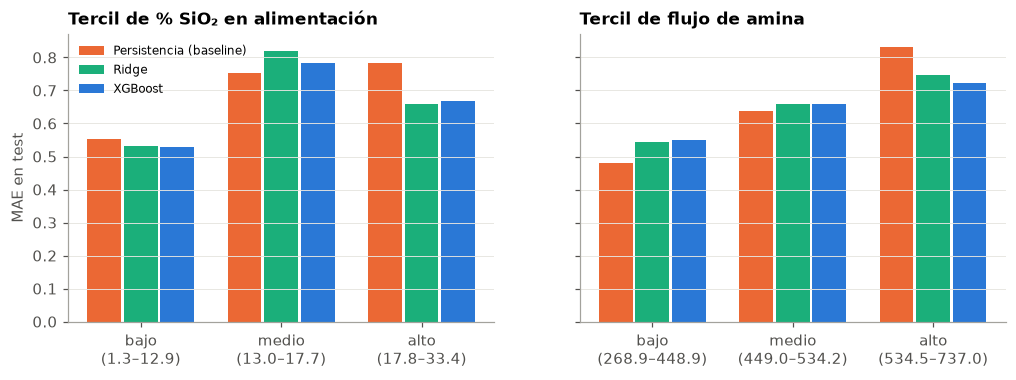

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, table, title in [(axes[0], regime_feed, "Tercil de % SiO₂ en alimentación"),
                         (axes[1], regime_amine, "Tercil de flujo de amina")]:
    x = np.arange(len(table))
    width = 0.26
    for i, (name, color) in enumerate(zip(eval_preds, [ORANGE, AQUA, BLUE])):
        ax.bar(x + (i - 1) * width, table[name], width=width * 0.92, color=color, label=name)
    ax.set_xticks(x, [f"{idx}\n({r})" for idx, r in zip(table.index, table["rango"])])
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("MAE en test")
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
save(fig, "05_error_por_regimen")
plt.show()

## 11. Residuos en el tiempo

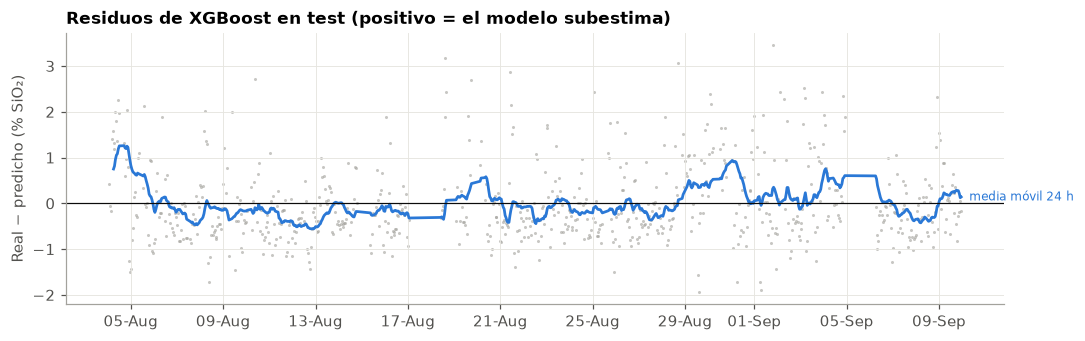

Sesgo medio: -0.018 | asimetría: 1.13
Autocorrelación de residuos (lag 1, 2, 3 h): [np.float64(0.53), np.float64(0.21), np.float64(0.14)]
Fracción de residuos > +1 punto (subestimación grande): 0.127 | < −1 punto: 0.057


In [25]:
residuals = y_test - predictions["XGBoost"]
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.scatter(residuals.index, residuals, s=4, color=GRAY, alpha=0.6, lw=0)
ax.plot(residuals.index, residuals.rolling(24, min_periods=6).mean(), color=BLUE, lw=1.8)
ax.axhline(0, color=TEXT, lw=0.8)
ax.text(residuals.index[-1], residuals.rolling(24, min_periods=6).mean().iloc[-1], "  media móvil 24 h",
        color=BLUE, fontsize=8, va="center")
ax.set_ylabel("Real − predicho (% SiO₂)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%b"))
ax.set_title("Residuos de XGBoost en test (positivo = el modelo subestima)")
save(fig, "05_residuos_tiempo")
plt.show()

print(f"Sesgo medio: {residuals.mean():+.3f} | asimetría: {residuals.skew():.2f}")
print("Autocorrelación de residuos (lag 1, 2, 3 h):",
      [round(residuals.asfreq('h').autocorr(k), 2) for k in (1, 2, 3)])
print("Fracción de residuos > +1 punto (subestimación grande):", round((residuals > 1).mean(), 3),
      "| < −1 punto:", round((residuals < -1).mean(), 3))

## 12. Intervalos de predicción (90 %)

Dos métodos, ambos sin tocar el test para calibrar:

1. **Regresión cuantílica con XGBoost**: cuantiles 5 % y 95 % (`reg:quantileerror`), con early stopping temporal.
2. **Conformal partido (split conformal)**: modelo puntual entrenado con el primer 80 % del train (que a su vez
   usa su último 20 % para early stopping); el último 20 % del train es el **set de calibración**, que el modelo
   no vio. El semiancho es el cuantil ⌈(n+1)·0,9⌉/n de los |residuos| de calibración.

Lo que importa es la **cobertura real en test** frente al 90 % nominal.

In [26]:
ALPHA = 0.10

quantile_model = fit_xgb_early_stopping(
    X_train, y_train, objective="reg:quantileerror",
    quantile_alpha=np.array([ALPHA / 2, 0.5, 1 - ALPHA / 2]), eval_metric="quantile")
q_pred = quantile_model.predict(X_test)
q_lower, q_upper = np.minimum(q_pred[:, 0], q_pred[:, 2]), np.maximum(q_pred[:, 0], q_pred[:, 2])

cal_cut = int(len(X_train) * 0.8)
point_model = fit_xgb_early_stopping(X_train.iloc[:cal_cut], y_train.iloc[:cal_cut])
cal_residuals = y_train.iloc[cal_cut:] - point_model.predict(X_train.iloc[cal_cut:])
halfwidth = conformal_halfwidth(cal_residuals, ALPHA)
c_center = point_model.predict(X_test)
c_lower, c_upper = c_center - halfwidth, c_center + halfwidth

print(f"Set de calibración: {len(cal_residuals)} h ({X_train.index[cal_cut]:%d-%b} → {X_train.index[-1]:%d-%b}); "
      f"semiancho conformal = ±{halfwidth:.2f}")
intervals = pd.DataFrame({
    "XGBoost cuantílico": interval_report(y_test, q_lower, q_upper, 1 - ALPHA),
    "Conformal partido": interval_report(y_test, c_lower, c_upper, 1 - ALPHA),
}).T
intervals.round(3)

Set de calibración: 518 h (07-Jul → 31-Jul); semiancho conformal = ±1.20


,cobertura_nominal,cobertura_real,ancho_medio
XGBoost cuantílico,0.9,0.900,2.693
Conformal partido,0.9,0.864,2.403


In [27]:
coverage_regime = pd.DataFrame({
    "XGBoost cuantílico": pd.Series((y_test >= q_lower) & (y_test <= q_upper), index=y_test.index),
    "Conformal partido": pd.Series((y_test >= c_lower) & (y_test <= c_upper), index=y_test.index),
})
sil_bins = pd.qcut(y_test, 3, labels=["sílice real baja", "media", "alta"])
print("Cobertura por tercil de la sílice REAL (diagnóstico: dónde fallan los intervalos):")
coverage_regime.groupby(sil_bins, observed=True).mean().round(3)

Cobertura por tercil de la sílice REAL (diagnóstico: dónde fallan los intervalos):


,XGBoost cuantílico,Conformal partido
% Silica Concentrate,,
sílice real baja,0.861,0.952
media,1.000,0.992
alta,0.838,0.639


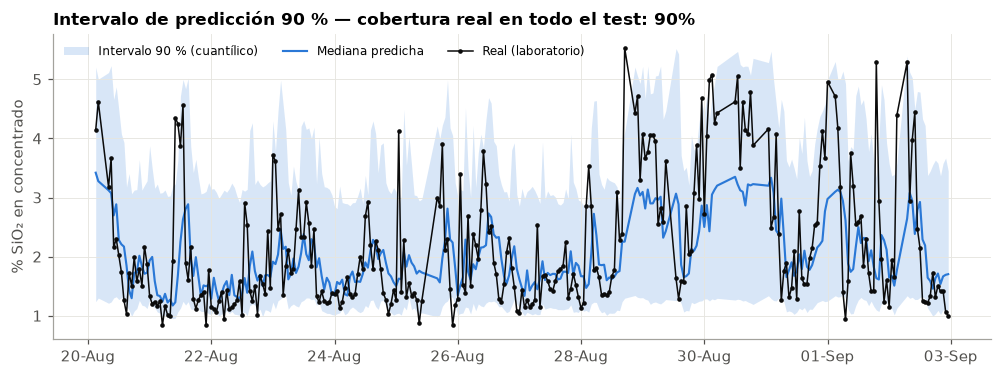

In [28]:
window = y_test.loc["2017-08-20":"2017-09-02"].index
pos = y_test.index.get_indexer(window)
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.fill_between(window, q_lower[pos], q_upper[pos], color=BLUE, alpha=0.18, lw=0, label="Intervalo 90 % (cuantílico)")
ax.plot(window, q_pred[pos, 1], color=BLUE, lw=1.4, label="Mediana predicha")
ax.plot(window, y_test[window], color=TEXT, lw=1, marker="o", ms=2, label="Real (laboratorio)")
ax.set_ylabel("% SiO₂ en concentrado")
ax.xaxis.set_major_locator(mdates.DayLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%b"))
ax.legend(frameon=False, ncol=3, loc="upper left", fontsize=8)
cov = intervals.loc["XGBoost cuantílico", "cobertura_real"]
ax.set_title(f"Intervalo de predicción 90 % — cobertura real en todo el test: {cov:.0%}")
save(fig, "05_intervalos")
plt.show()

## 13. SHAP: qué usa el modelo

Valores SHAP exactos para árboles (`TreeExplainer`) del XGBoost final, calculados sobre el test.
**SHAP explica al modelo, no a la planta**: un signo describe lo que el modelo aprendió de los datos
históricos, incluidas las reacciones de control.

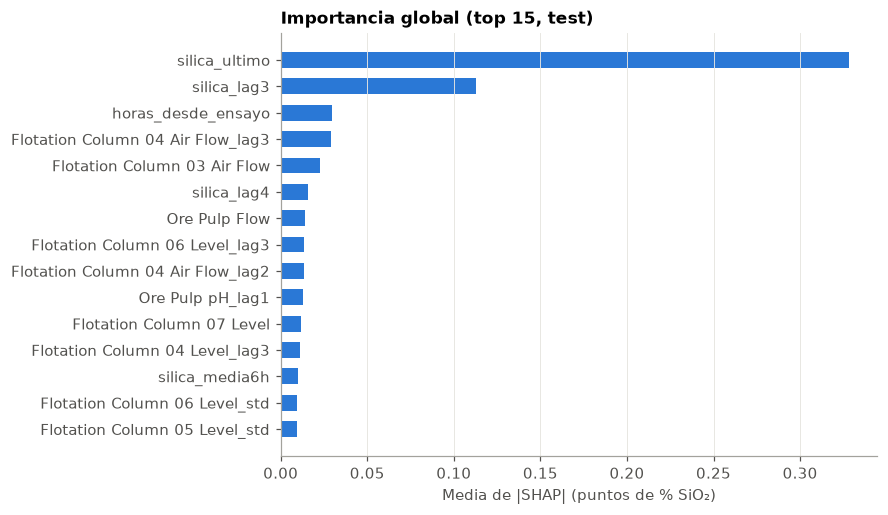

Fracción de la importancia total en la historia de sílice (5 features): 55%


In [29]:
explainer = shap.TreeExplainer(xgb)
shap_values = pd.DataFrame(explainer.shap_values(X_test), index=X_test.index, columns=X_test.columns)
importance = shap_values.abs().mean().sort_values(ascending=False)

top = importance.head(15)[::-1]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top.index, top, color=BLUE, height=0.6)
ax.set_xlabel("Media de |SHAP| (puntos de % SiO₂)")
ax.set_title("Importancia global (top 15, test)")
ax.grid(axis="y", visible=False)
save(fig, "05_shap_importancia")
plt.show()

share_silica = importance[silica_cols].sum() / importance.sum()
print(f"Fracción de la importancia total en la historia de sílice ({len(silica_cols)} features): {share_silica:.0%}")

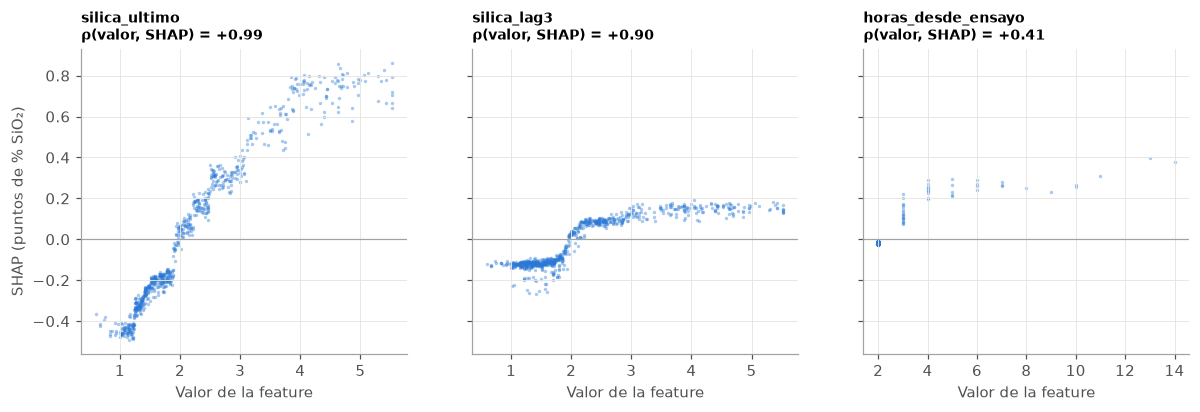

In [30]:
top3 = importance.index[:3]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, col in zip(axes, top3):
    ax.scatter(X_test[col], shap_values[col], s=5, color=BLUE, alpha=0.4, lw=0)
    ax.axhline(0, color=GRAY, lw=0.8)
    rho = X_test[col].corr(shap_values[col], method="spearman")
    ax.set_title(f"{col}\nρ(valor, SHAP) = {rho:+.2f}", fontsize=9)
    ax.set_xlabel("Valor de la feature")
axes[0].set_ylabel("SHAP (puntos de % SiO₂)")
save(fig, "05_shap_dependencia_top3")
plt.show()

In [31]:
physical_checks = {
    "silica_ultimo": "+ (inercia: sílice alta tiende a seguir alta)",
    "Amina Flow": "− si fuera causa física (más colector flota más sílice); + si es reacción del operador",
    "Ore Pulp pH": "− (pH más alto mejora la selectividad de la amina por el cuarzo)",
    "Ore Pulp Density": "+ (más sólidos → más arrastre de ganga al concentrado)",
    "Starch Flow": "≈0 o + (el almidón deprime el hierro; en exceso puede deprimir cuarzo)",
    "Flotation Column 03 Air Flow": "− (más aire → más sílice flotada → menos sílice en el concentrado)",
    "Ore Pulp Flow": "+ (más flujo → menos tiempo de residencia → peor separación)",
}

def strongest_version(base):
    # la versión (t, rezagos, desviación) que más usa el modelo
    versions = [c for c in X_test.columns if c == base or c.startswith(base + "_")]
    return max(versions, key=lambda c: importance[c])

rows_sign = []
for base, expected in physical_checks.items():
    col = strongest_version(base)
    rows_sign.append({"variable": base, "version_mas_usada": col,
                      "rank": int(importance.index.get_loc(col)) + 1,
                      "media_abs_shap": importance[col],
                      "signo_aprendido_rho": X_test[col].corr(shap_values[col], method="spearman"),
                      "esperado_fisico": expected})
pd.DataFrame(rows_sign).set_index("variable").round(3)

,version_mas_usada,rank,media_abs_shap,signo_aprendido_rho,esperado_fisico
variable,,,,,
silica_ultimo,silica_ultimo,1,0.328,0.987,+ (inercia: sílice alta tiende a seguir alta)
Amina Flow,Amina Flow,25,0.006,-0.060,− si fuera causa física (más colector flota má...
Ore Pulp pH,Ore Pulp pH_lag1,10,0.013,-0.795,− (pH más alto mejora la selectividad de la am...
Ore Pulp Density,Ore Pulp Density_lag3,16,0.009,0.639,+ (más sólidos → más arrastre de ganga al conc...
Starch Flow,Starch Flow_lag3,19,0.008,0.385,≈0 o + (el almidón deprime el hierro; en exces...
Flotation Column 03 Air Flow,Flotation Column 03 Air Flow,5,0.023,0.033,− (más aire → más sílice flotada → menos sílic...
Ore Pulp Flow,Ore Pulp Flow,7,0.014,-0.491,+ (más flujo → menos tiempo de residencia → pe...
